## **Import Library**

In [1]:
import os
import math
import shutil
from google.colab import files

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, Conv2D, MaxPooling2D, BatchNormalization, GlobalAveragePooling2D, SpatialDropout2D, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import Model
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import TFSMLayer

## **Download Dataset**

In [2]:
!kaggle datasets download sumn2u/garbage-classification-v2
!unzip -q -o garbage-classification-v2.zip

Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
100% 1.07G/1.07G [00:14<00:00, 77.3MB/s]



In [3]:
path = 'original'

In [4]:
data = []

for label in os.listdir(path):
  labelPath = f'{path}/{label}'
  for img in os.listdir(labelPath):
    imgPath = f'{labelPath}/{img}'
    data.append({
      'file_path': imgPath,
      'label': label
    })

df = pd.DataFrame(data)
df

,file_path,label
0,original/cardboard/cardboard_377.jpg,cardboard
1,original/cardboard/cardboard_528.jpg,cardboard
2,original/cardboard/cardboard_1076.jpg,cardboard
3,original/cardboard/cardboard_924.jpg,cardboard
4,original/cardboard/cardboard_861.jpg,cardboard
...,...,...
12254,original/clothes/clothes_1531.jpg,clothes
12255,original/clothes/clothes_1241.jpg,clothes
12256,original/clothes/clothes_1213.jpg,clothes
12257,original/clothes/clothes_1517.jpg,clothes


In [5]:
NUM_CLASSES = df['label'].nunique()

## **Dataset Exploration**

In [6]:
def print_images_sample(directory):
  labels = os.listdir(directory)
  labels = sorted(labels)

  n_labels = len(labels)
  n_cols = 5

  fig, axes = plt.subplots(n_labels, n_cols, figsize=(10, 8))

  for i, label in enumerate(labels):
    labelPath = f'{directory}/{label}'

    for j in range(n_cols):
      imgFile = os.listdir(labelPath)[j]
      imgPath = f'{labelPath}/{imgFile}'

      img = Image.open(imgPath)
      w, h = img.size

      axes[i, j].imshow(img)
      axes[i, j].set(xlabel=f'{label} ({w} x {h})', xticks=[], yticks=[])

  plt.tight_layout()
  plt.show()

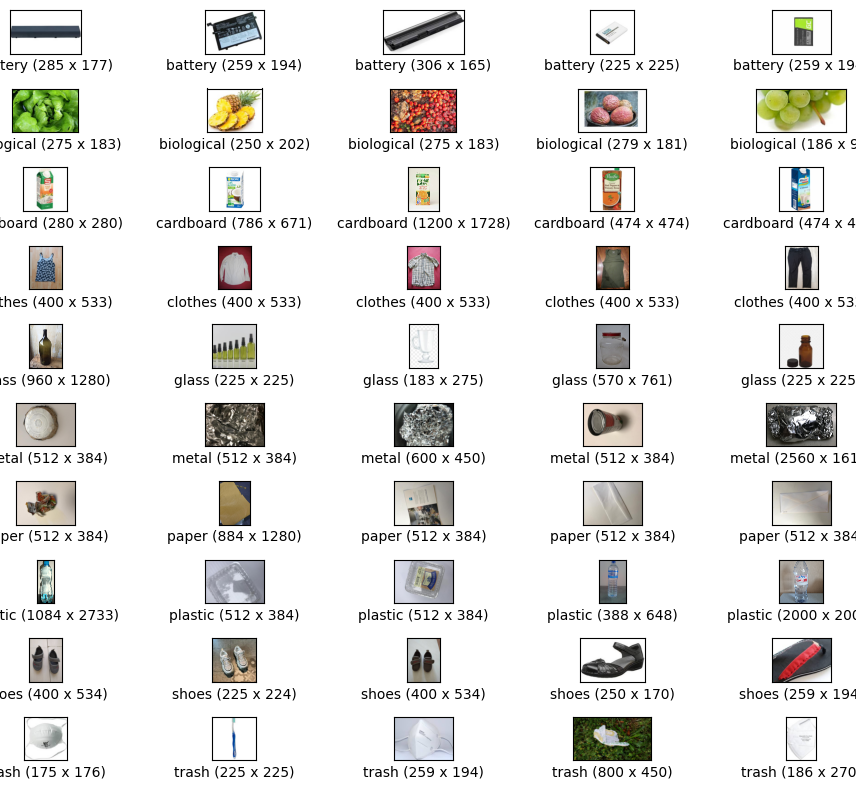

In [7]:
print_images_sample(path)

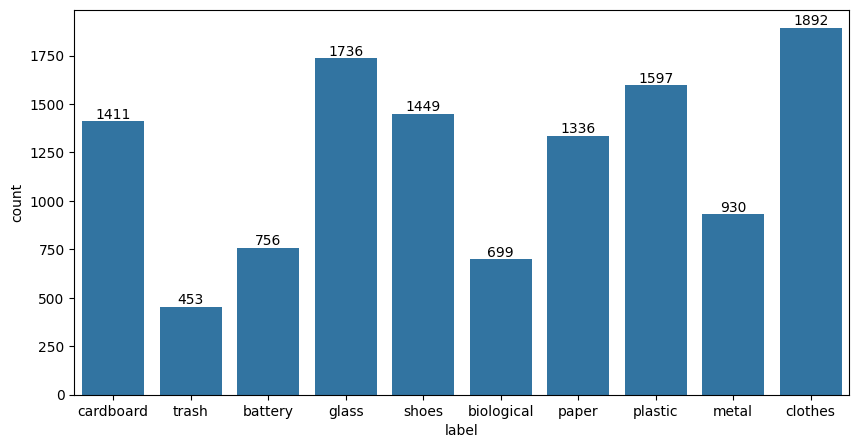

In [8]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='label', data=df)
ax.bar_label(ax.containers[0])
plt.show()

## **Dataset Splitting**

In [9]:
X = df['file_path']
y = df['label']

X_train, X_test_val, y_train, y_test_val = train_test_split(
  X, y,
  test_size=0.3,
  stratify=y,
  random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
  X_test_val, y_test_val,
  test_size=0.5,
  stratify=y_test_val,
  random_state=42
)

In [10]:
train_df = pd.DataFrame({'file_path': X_train, 'label': y_train})
val_df = pd.DataFrame({'file_path': X_val, 'label': y_val})
test_df = pd.DataFrame({'file_path': X_test, 'label': y_test})

## **Image Normalization**

### **Manual Normalization**

In [11]:
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [12]:
TARGET_SIZE = (224, 224)
BATCH_SIZE = 32

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='file_path',
    y_col='label',
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    color_mode='rgb',
    class_mode='sparse',
    shuffle=True,
    seed=42
)

# train_eval_generator = train_datagen.flow_from_dataframe(
#     train_df,
#     x_col='file_path',
#     y_col='label',
#     batch_size=BATCH_SIZE,
#     target_size=TARGET_SIZE,
#     color_mode='rgb',
#     class_mode='sparse',
#     shuffle=False,
#     seed=42
# )

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='file_path',
    y_col='label',
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    color_mode='rgb',
    class_mode='sparse',
    shuffle=False
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='file_path',
    y_col='label',
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    color_mode='rgb',
    class_mode='sparse',
    shuffle=False
)

Found 8581 validated image filenames belonging to 10 classes.
Found 1839 validated image filenames belonging to 10 classes.
Found 1839 validated image filenames belonging to 10 classes.


### **EfficientNet Normalization**

In [13]:
train_datagen_fn = ImageDataGenerator(preprocessing_function=preprocess_input)
val_datagen_fn = ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen_fn = ImageDataGenerator(preprocessing_function=preprocess_input)

In [14]:
train_generator_fn = train_datagen_fn.flow_from_dataframe(
    train_df,
    x_col="file_path",
    y_col="label",
    batch_size=32,
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="sparse",
    shuffle=True,
    seed=42
)

train_eval_generator_fn = train_datagen_fn.flow_from_dataframe(
    train_df,
    x_col='file_path',
    y_col='label',
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    color_mode='rgb',
    class_mode='sparse',
    shuffle=False,
    seed=42
)

val_generator_fn = val_datagen_fn.flow_from_dataframe(
    val_df,
    x_col="file_path",
    y_col="label",
    batch_size=32,
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="sparse",
    shuffle=False
)

test_generator_fn = test_datagen_fn.flow_from_dataframe(
      test_df,
      x_col="file_path",
      y_col="label",
      batch_size=32,
      target_size=(224, 224),
      color_mode="rgb",
      class_mode="sparse",
      shuffle=False
)

Found 8581 validated image filenames belonging to 10 classes.
Found 8581 validated image filenames belonging to 10 classes.
Found 1839 validated image filenames belonging to 10 classes.
Found 1839 validated image filenames belonging to 10 classes.


## **Model Building**

In [15]:
def get_callbacks():
  early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
  )

  lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
  )

  return [early_stop, lr_scheduler]

In [16]:
def plot_history(history):
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  axes[0].plot(history.history['loss'], label='train_loss')
  axes[0].plot(history.history['val_loss'], label='val_loss')
  axes[0].set_xlabel('Epoch')
  axes[0].set_ylabel('Loss')
  axes[0].legend()
  axes[0].grid()

  axes[1].plot(history.history['accuracy'], label='train_acc')
  axes[1].plot(history.history['val_accuracy'], label='val_acc')
  axes[1].set_xlabel('Epoch')
  axes[1].set_ylabel('Accuracy')
  axes[1].legend()
  axes[1].grid()

  plt.show()

### **Multi Layer Perceptron**

In [ ]:
input = Input(shape=(224, 224, 3))

x = Flatten()(input)
x = Dense(256, activation='relu')(x)
x = Dropout(0.1)(x)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
x = BatchNormalization()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.2)(x)
x = BatchNormalization()(x)

out = Dense(NUM_CLASSES, activation='softmax')(x)

mlp_model = Model(inputs=input, outputs=out)
mlp_model.compile(
  optimizer=Adam(learning_rate=1e-4),
  loss=SparseCategoricalCrossentropy(),
  metrics=['accuracy']
)

mlp_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │    38,535,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,579,018 (147.17 MB)

 Trainable params: 38,578,122 (147.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
mlp_model_history = mlp_model.fit(
  train_generator,
  validation_data=val_generator,
  epochs=100,
  callbacks=get_callbacks()
)

Epoch 1/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 50s 169ms/step - accuracy: 0.1872 - loss: 2.5284 - val_accuracy: 0.2338 - val_loss: 2.2812 - learning_rate: 1.0000e-04
Epoch 2/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 40s 149ms/step - accuracy: 0.2423 - loss: 2.3000 - val_accuracy: 0.2518 - val_loss: 2.2654 - learning_rate: 1.0000e-04
Epoch 3/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 39s 144ms/step - accuracy: 0.2578 - loss: 2.2305 - val_accuracy: 0.2904 - val_loss: 1.9900 - learning_rate: 1.0000e-04
Epoch 4/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 39s 145ms/step - accuracy: 0.2648 - loss: 2.1745 - val_accuracy: 0.2126 - val_loss: 2.4745 - learning_rate: 1.0000e-04
Epoch 5/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 151ms/step - accuracy: 0.2608 - loss: 2.1373 - val_accuracy: 0.2561 - val_loss: 2.2223 - learning_rate: 1.0000e-04
Epoch 6/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 39s 146ms/step - accuracy: 0.2790 - loss: 2.1019 - val_accuracy: 0.2811 - val_loss: 2.0935 - learning_rate: 1.0000e-04
Epoch 7/100
269/269 ━━━━━━━━━━━━━━━━━━━━

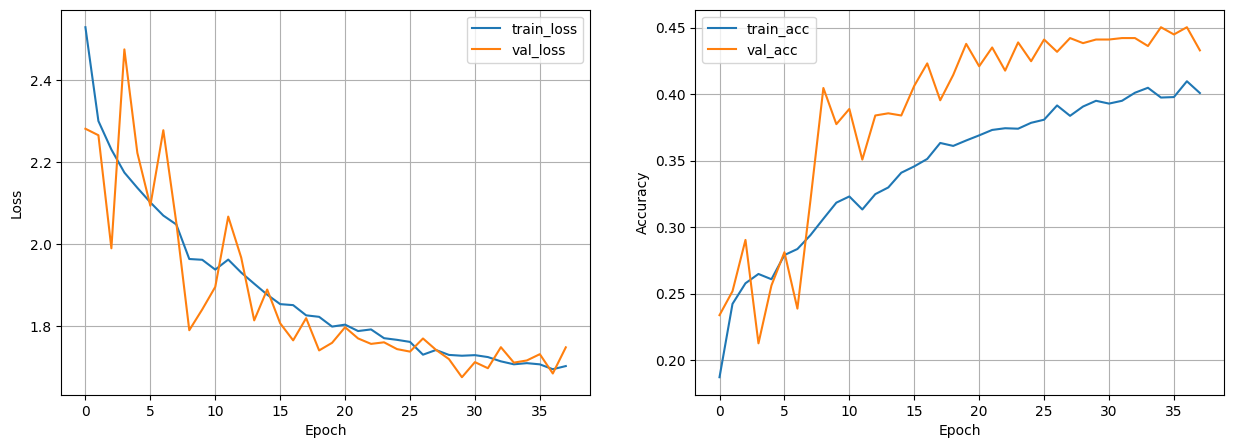

In [ ]:
plot_history(mlp_model_history)

### **CNN**

In [ ]:
input = Input(shape=(224, 224, 3))

x = Conv2D(32, (3, 3), padding='same', activation='relu')(input)
x = BatchNormalization()(x)
x = SpatialDropout2D(0.1)(x)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = SpatialDropout2D(0.1)(x)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = SpatialDropout2D(0.2)(x)
x = MaxPooling2D((2, 2))(x)

x = Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = SpatialDropout2D(0.2)(x)
x = MaxPooling2D((2, 2))(x)

x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
x = BatchNormalization()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.1)(x)
x = BatchNormalization()(x)

out = Dense(NUM_CLASSES, activation='softmax')(x)

cnn_model = Model(inputs=input, outputs=out)
cnn_model.compile(
  optimizer=Adam(learning_rate=1e-3),
  loss=SparseCategoricalCrossentropy(),
  metrics=['accuracy']
)

cnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 224, 224, 32)   │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 112, 112, 64)   │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_2             │ (None, 56, 56, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_3             │ (None, 28, 28, 256)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 432,906 (1.65 MB)

 Trainable params: 431,562 (1.65 MB)

 Non-trainable params: 1,344 (5.25 KB)

In [ ]:
cnn_model_history = cnn_model.fit(
  train_generator,
  validation_data=val_generator,
  epochs=100,
  callbacks=get_callbacks()
)

Epoch 1/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 86s 243ms/step - accuracy: 0.3012 - loss: 2.0659 - val_accuracy: 0.1735 - val_loss: 2.5569 - learning_rate: 0.0010
Epoch 2/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 46s 172ms/step - accuracy: 0.3759 - loss: 1.7969 - val_accuracy: 0.4100 - val_loss: 1.6641 - learning_rate: 0.0010
Epoch 3/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 46s 171ms/step - accuracy: 0.4010 - loss: 1.7162 - val_accuracy: 0.3322 - val_loss: 1.9422 - learning_rate: 0.0010
Epoch 4/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 47s 174ms/step - accuracy: 0.4307 - loss: 1.6377 - val_accuracy: 0.3915 - val_loss: 1.6682 - learning_rate: 0.0010
Epoch 5/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 180ms/step - accuracy: 0.4489 - loss: 1.5867 - val_accuracy: 0.4628 - val_loss: 1.5349 - learning_rate: 0.0010
Epoch 6/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 44s 163ms/step - accuracy: 0.4579 - loss: 1.5565 - val_accuracy: 0.4747 - val_loss: 1.5244 - learning_rate: 0.0010
Epoch 7/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 47s 176ms/step - accura

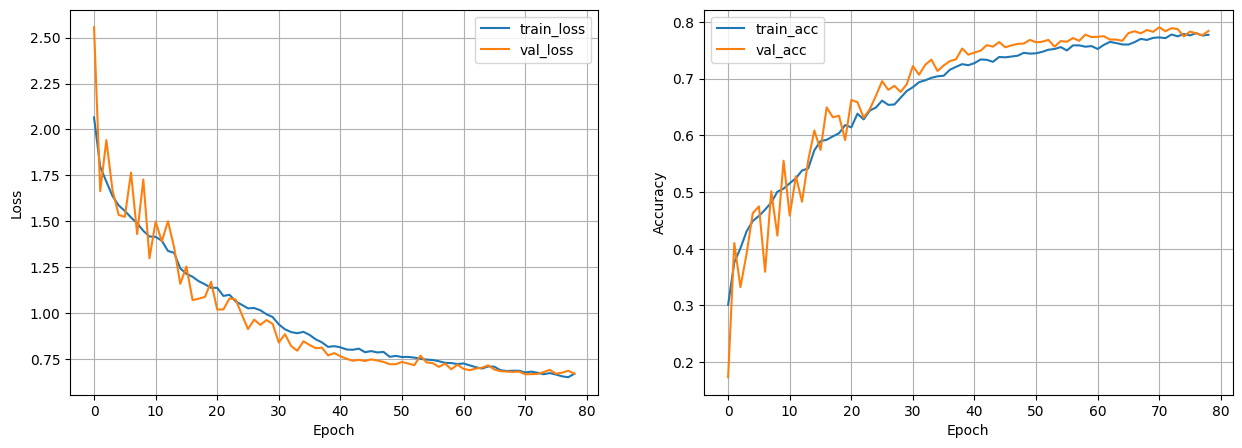

In [ ]:
plot_history(cnn_model_history)

### **EfficientNet**

In [17]:
efficientnet = EfficientNetV2B0(
  include_top=False,
  weights="imagenet"
)

efficientnet.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetv2-b0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, None,      │          0 │ input_layer[0][0] │
│ (Rescaling)         │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, None,      │          0 │ rescaling[0][0]   │
│ (Normalization)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, None,      │        864 │ normalization[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, None,      │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, None,      │          0 │ stem_bn[0][0]     │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, None,      │      4,608 │ stem_activation[… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, None,      │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, None,      │          0 │ block1a_project_… │
│ (Activation)        │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, None,      │      9,216 │ block1a_project_… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, None,      │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, None,      │          0 │ block2a_expand_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, None,      │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, None,      │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, None,      │     36,864 │ block2a_project_… │
│ (Conv2D)            │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, None,      │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, None,      │          0 │ block2b_expand_b

 Total params: 5,919,312 (22.58 MB)

 Trainable params: 5,858,704 (22.35 MB)

 Non-trainable params: 60,608 (236.75 KB)

In [18]:
efficientnet.trainable = True

for layer in efficientnet.layers[:-30]:
  layer.trainable = False

In [19]:
input = Input(shape=(224, 224, 3))

x = efficientnet(input)
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)

out = Dense(NUM_CLASSES, activation='softmax')(x)

fn_model = Model(inputs=input, outputs=out)
fn_model.compile(
  optimizer=Adam(learning_rate=1e-5),
  loss=SparseCategoricalCrossentropy(),
  metrics=['accuracy']
)

fn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,001,946 (22.90 MB)

 Trainable params: 1,246,506 (4.76 MB)

 Non-trainable params: 4,755,440 (18.14 MB)

In [21]:
fn_model_history = fn_model.fit(
  train_generator_fn,
  validation_data=val_generator_fn,
  epochs=100,
  callbacks=get_callbacks()
)

Epoch 1/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 119s 295ms/step - accuracy: 0.1855 - loss: 2.2405 - val_accuracy: 0.4568 - val_loss: 1.9574 - learning_rate: 1.0000e-05
Epoch 2/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 45s 167ms/step - accuracy: 0.4083 - loss: 1.8523 - val_accuracy: 0.6683 - val_loss: 1.5956 - learning_rate: 1.0000e-05
Epoch 3/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 46s 171ms/step - accuracy: 0.5572 - loss: 1.5189 - val_accuracy: 0.7504 - val_loss: 1.2789 - learning_rate: 1.0000e-05
Epoch 4/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 46s 171ms/step - accuracy: 0.6397 - loss: 1.2852 - val_accuracy: 0.7939 - val_loss: 1.0713 - learning_rate: 1.0000e-05
Epoch 5/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 44s 164ms/step - accuracy: 0.7019 - loss: 1.1044 - val_accuracy: 0.8151 - val_loss: 0.9293 - learning_rate: 1.0000e-05
Epoch 6/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 42s 157ms/step - accuracy: 0.7281 - loss: 0.9793 - val_accuracy: 0.8401 - val_loss: 0.8103 - learning_rate: 1.0000e-05
Epoch 7/100
269/269 ━━━━━━━━━━━━━━━━━━━

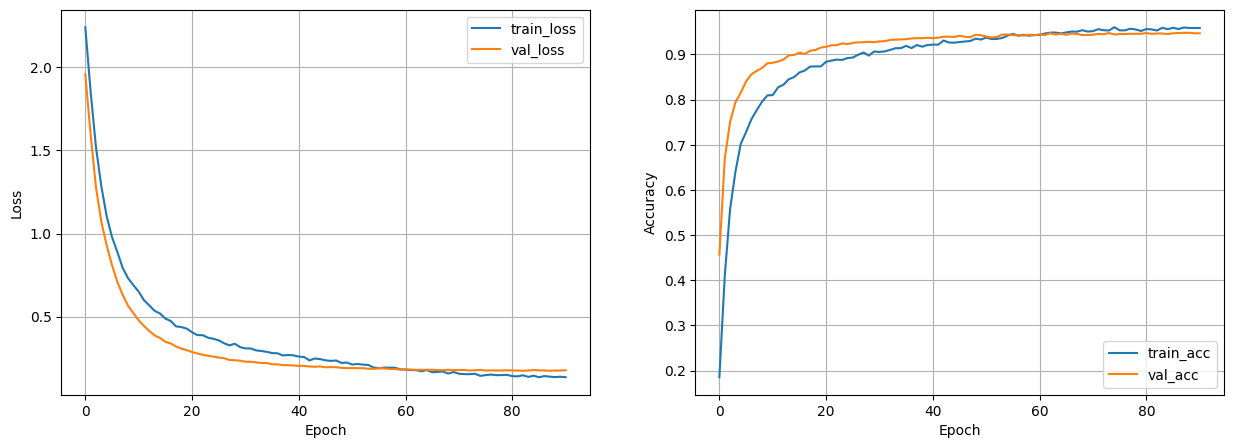

In [22]:
plot_history(fn_model_history)

## **Model Evaluation**

In [23]:
labels = list(train_generator.class_indices.keys())
y_true = test_generator.labels

In [24]:
def evaluate_model(y_pred):
  eval = {
    'accuracy': accuracy_score(y_true, y_pred),
    'recall': recall_score(y_true, y_pred, average='macro'),
    'precision': precision_score(y_true, y_pred, average='macro'),
    'f1_score': f1_score(y_true, y_pred, average='macro')
  }

  eval = pd.DataFrame([eval])
  return eval

In [25]:
def plot_cm(y_pred):
  cm = confusion_matrix(y_true, y_pred)

  cmd = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
  )
  cmd.plot(cmap=plt.cm.Blues)

  plt.title('Confusion Matrix', weight='bold', pad=20)
  plt.xticks(rotation=90)
  plt.show()

### **Multi Layer Perceptron**

In [ ]:
y_pred = mlp_model.predict(test_generator).argmax(axis=1)

evaluate_model(y_pred)

58/58 ━━━━━━━━━━━━━━━━━━━━ 8s 132ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,recall,precision,f1_score
0,0.430125,0.375897,0.391472,0.369938


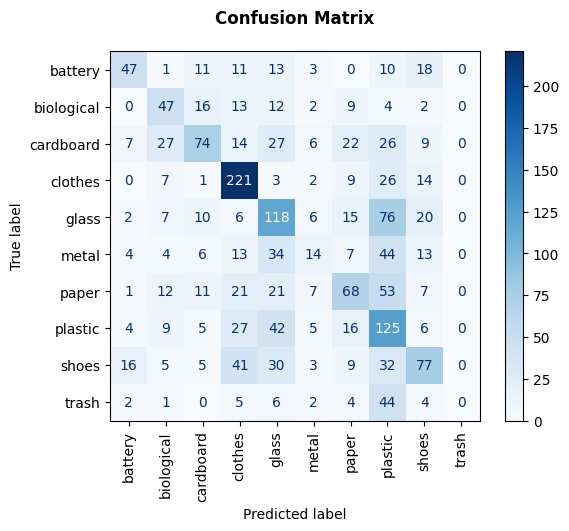

In [ ]:
plot_cm(y_pred)

### **CNN**

In [ ]:
y_pred = cnn_model.predict(test_generator).argmax(axis=1)

evaluate_model(y_pred)

58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step


,accuracy,recall,precision,f1_score
0,0.797172,0.772702,0.798073,0.78254


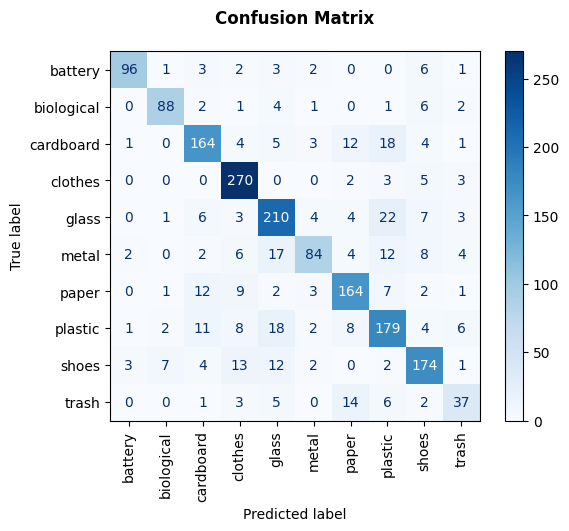

In [ ]:
plot_cm(y_pred)

### **EfficientNet**

In [26]:
y_pred = fn_model.predict(test_generator_fn).argmax(axis=1)

evaluate_model(y_pred)

58/58 ━━━━━━━━━━━━━━━━━━━━ 20s 229ms/step


,accuracy,recall,precision,f1_score
0,0.941816,0.938824,0.934251,0.936401


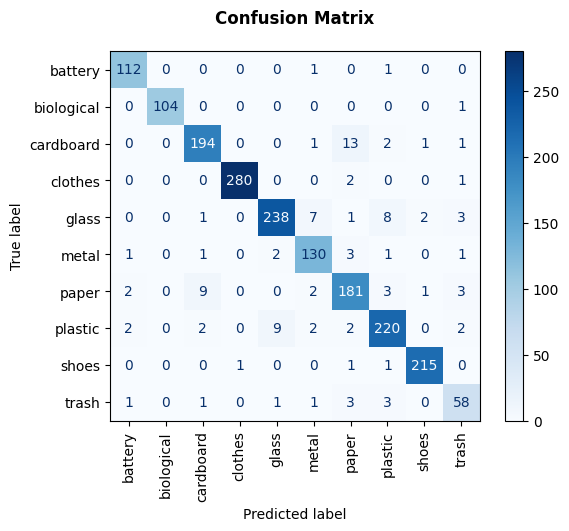

In [27]:
plot_cm(y_pred)

## **Save Model**

In [28]:
fn_model.export('saved_model/')

Saved artifact at 'saved_model/'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_270')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  136454015083216: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136454015083408: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136454015080528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015078416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015078992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015077072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015078800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015083024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015076880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136454015078608: TensorSpec(shape=(), dtype=tf.resource, name=Non

In [29]:
with open('./saved_model/labels.txt', 'w') as f:
  for label in labels:
    f.write(f"{label}\n")

In [30]:
shutil.make_archive('saved_model', 'zip', './saved_model')

'/content/saved_model.zip'

## **Inference**

In [31]:
def preprocess(img):
  img = Image.open(img)
  img = img.resize((224, 224))
  img = np.array(img, dtype=np.float32)
  img = np.expand_dims(img, axis=0)
  img = preprocess_input(img)

  return img

In [32]:
def classify(img):
  with open('./saved_model/labels.txt', 'r') as f:
    labels = [a.replace('\n', '') for a in f.readlines()]

  img = preprocess(img)
  loaded_model = TFSMLayer('saved_model/', call_endpoint='serving_default')

  prediction = loaded_model(img)
  prediction = list(prediction.values())[0]
  predicted_class_index = np.argmax(prediction[0])
  predicted_label = labels[predicted_class_index]

  return predicted_label

Saving aqua.webp to aqua.webp


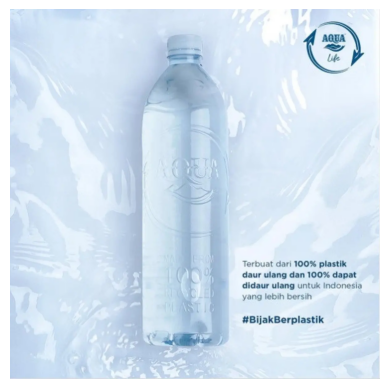

Classified as: plastic


In [33]:
img_file = ""
uploaded = files.upload()
for key in uploaded.keys():
  img_file = key

img = Image.open(img_file)
plt.imshow(img)
plt.axis('off')
plt.show()

result = classify(img_file)
print(f'Classified as: {result}')